# 06h. Case study: the summer 2012 central U.S. heat wave: sensitivity of the event definition

The calendar-day threshold recomputed from other ERA5 reference periods (`sens_threshold_years`, `exclude_years` left out) and percentiles (`sens_percentiles`), on the fixed event window: observed hot days and longest run, and the event probability of each scored experiment and start. Absolute temperatures are compared with the absolute threshold (no climatology involved).

## Limitations and next steps

* **One event, overlapping starts.** Four starts five days apart of one event: the scores are case-specific sensitivities, not climatological forecast skill, and the Brier score of one observed event says nothing about reliability, discrimination or false alarms.
* **Reference state.** No lead-dependent hindcast climatology exists for these starts; the AMIP adjustment removes only the background model mean difference. The threshold and climatologies use 2001-2014 without 2012; notebook `06h` shows how much the event definition depends on that choice.
* **Prescribed observed SST.** Every experiment shares the observed SST, so differences come from the atmosphere and land initial states and their evolution only.
* **Excluded experiments.** HYB_BASE and DA_LND (`ic_defect`) answer nothing until rerun; Q2 and the DA_LND part of Q3 remain open.
* **Mechanism (next notebook).** Where the scored experiments underestimate sustained heat while producing more event precipitation than GPCP, that is a working hypothesis to test, not a cause: antecedent precipitation and soil moisture, latent and sensible heat fluxes, net radiation and cloud, and the location and persistence of the ridge (Z500). Similar pooled DA_COUPLED and DA_ATM results call for the start-resolved contrasts above before concluding that land initialization has little effect.

**The 06a-06h series** (summer 2012 central U.S. heat wave; each notebook reads the data it needs, computes, saves, then plots): `06a` observed event and simulation coverage; `06b` experiment QC; `06c` start-resolved regional trajectories; `06d` fixed-event-window metrics and maps; `06e` S2S lead-window scores; `06f` event probability; `06g` initialization contrasts; `06h` sensitivity of the event definition. Settings: `HeatwaveSettings` in `configs/hind_lead_eval_cases.py`; products: `util/heatwave_workflow.py`; methods: `util/heatwave_case.py`. Design, event definition and reference states: `06a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/heatwave_2012/threshold_sensitivity.csv`; figure `heatwave_threshold_sensitivity.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the HeatwaveSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"event_window": ("2012-06-27", "2012-07-07")}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import HeatwaveSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.heatwave_workflow import HeatwaveCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = HeatwaveCase(HeatwaveSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (`observed_fields.nc`), and from them the observed events and the event window. Then the daily TREFHT (mean of the four 6-hour means) and PRECT of every member on the map box (`box_<CONFIG>_<SEASON>_<VAR>.nc`), put on calendar days, and their regional means: absolute temperature, anomalies against both references (`biases`), area fraction above the gridpoint threshold, and precipitation (daily and accumulated from the start).

In [4]:
obs = case.obs
print(f"[REGION] {cfg.region['name']}: {int(obs.mask.sum())} land points\n[CLIM] observed: {obs.clim_sources[0]}\n"
      f"[CLIM] model: {obs.clim_sources[1]}")
series = case.series

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_fields.nc
[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))


[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[SERIES] 20 (config, start) pairs, 40 anomaly series


## 5. Process and save

The thresholds of every reference period and percentile, the observed hot days and longest run, and the event probability of each scored experiment and start (`threshold_sensitivity.csv`).

In [5]:
sens = case.threshold_sensitivity()
display(sens.drop_duplicates(["threshold_years", "percentile"])[["threshold_years", "percentile", "obs_hot_days",
                                                                 "obs_longest_run"]])
p_event = (sens.pivot(index=["threshold_years", "percentile"], columns=["config", "init"], values="p_event")
           .reindex(columns=case.scored, level="config"))
display(p_event.round(2))

[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/threshold_sensitivity.csv: built with other settings, recomputing


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/threshold_sensitivity.csv


,threshold_years,percentile,obs_hot_days,obs_longest_run
0,2001-2014,0.85,11,11
12,2001-2014,0.90,11,11
24,2001-2014,0.95,11,11
36,1991-2020,0.85,11,11
48,1991-2020,0.90,11,11
60,1991-2020,0.95,11,11


config                      CLIM_BASE                                   \
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31   
threshold_years percentile                                               
1991-2020       0.85             0.40       0.75        0.7       0.60   
                0.90             0.35       0.50        0.6       0.45   
                0.95             0.30       0.35        0.5       0.35   
2001-2014       0.85             0.50       0.80        0.7       0.65   
                0.90             0.35       0.55        0.6       0.50   
                0.95             0.30       0.30        0.5       0.35   

config                     DA_COUPLED                                   \
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31   
threshold_years percentile                                               
1991-2020       0.85             0.60       0.80       0.65       0.75   
                0.90             0.45       0.65       0.40       0.60   
                0.95             0.35       0.60       0.35       0.35   
2001-2014       0.85             0.65       0.80       0.65       0.75   
                0.90             0.55       0.75       0.45       0.70   
                0.95             0.35       0.60       0.35       0.35   

config                         DA_ATM                                   
init                       2012-05-16 2012-05-21 2012-05-26 2012-05-31  
threshold_years percentile                                              
1991-2020       0.85             0.80       0.65       0.70       0.70  
                0.90             0.70       0.65       0.50       0.60  
                0.95             0.55       0.55       0.45       0.50  
2001-2014       0.85             0.80       0.65       0.65       0.75  
                0.90             0.75       0.65       0.50       0.60  
                0.95             0.55       0.55       0.45       0.55

## 6. Plot and show

Event probability per start for every threshold choice, one panel per scored experiment.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_threshold_sensitivity.png


PosixPath('/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_threshold_sensitivity.png')

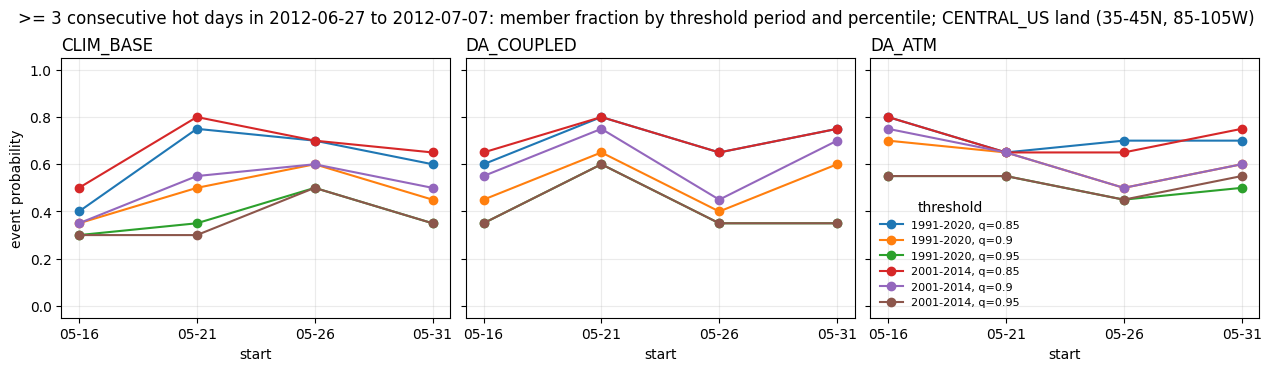

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(case.scored), figsize=(4.2 * len(case.scored), 3.6), sharey=True,
                         constrained_layout=True, squeeze=False)
for ax, c in zip(axes[0], case.scored):
    for (years, q), row in p_event[c].iterrows():
        ax.plot(range(len(row)), row.values, marker="o", label=f"{years}, q={q:g}")
    ax.set_xticks(range(len(case.inits)), [str(i)[5:10] for i in case.inits])
    ax.set_title(c, loc="left")
    ax.set_xlabel("start")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.25)
axes[0][0].set_ylabel("event probability")
axes[0][-1].legend(frameon=False, fontsize=8, title="threshold")
fig.suptitle(f">= {cfg.min_event_days} consecutive hot days in {obs.window[0]} to {obs.window[1]}: member fraction by "
             f"threshold period and percentile; {case.label}")
save(fig, "heatwave_threshold_sensitivity.png")